# Klasifikasi Citra Sepatu (Rapi vs. Berantakan)
### Ekstraksi Fitur Statistik Orde Pertama (Warna RGB) dan Orde Kedua (Tekstur GLCM) dengan Kerangka CRISP-DM

| Parameter | Keterangan |
| :--- | :--- |
| **Domain Masalah** | Pengolahan Citra Digital (*Computer Vision*) |
| **Kasus** | Klasifikasi biner foto susunan sepatu: **Rapi** vs. **Berantakan** |
| **Dataset** | Folder `citra/`: **173 citra** (76 rapi, 97 berantakan) |
| **Preprocessing** | Konversi BGR → RGB, *resize* 256 × 256 piksel |
| **Fitur Orde Pertama (9)** | *Mean*, standar deviasi, dan *skewness* pada kanal R, G, B |
| **Konversi Grayscale** | $0.299R + 0.587G + 0.114B$, 8 bit (256 level), disimpan ke folder `grayscale/` |
| **Matriks Co-occurrence** | GLCM jarak $d = 1$, sudut $\theta = 0^\circ$, 256 level, `symmetric=False`, `normed=True` (sesuai modul) |
| **Fitur Orde Kedua (5)** | Energi, entropi, kontras, korelasi, homogenitas |
| **Keluaran Akhir** | `hasil/fitur_lengkap.csv`: **173 baris × 14 fitur + label** |

## TAHAP 1: BUSINESS UNDERSTANDING (Pemahaman Masalah)

### 1.1 Latar Belakang Masalah
Kerapian susunan sepatu di rak atau area pintu masuk mencerminkan keteraturan sebuah ruangan. Selama ini kerapian dinilai secara manual, yang memiliki beberapa kelemahan:
1. **Subjektif**: batas antara "rapi" dan "berantakan" berbeda bagi setiap orang.
2. **Tidak terukur**: penilaian manual tidak menghasilkan angka yang bisa dibandingkan atau diolah lebih lanjut.
3. **Kebutuhan otomatisasi**: agar komputer dapat menilai kerapian, setiap foto harus diubah menjadi **representasi numerik (fitur)** terlebih dahulu.

### 1.2 Rumusan Masalah
1. Bagaimana menghitung fitur statistik orde pertama (*mean*, standar deviasi, *skewness*) pada setiap kanal warna citra sepatu?
2. Bagaimana mengubah citra berwarna menjadi citra grayscale 8 bit dan membentuk matriks *co-occurrence* (GLCM)-nya?
3. Bagaimana menghitung fitur tekstur orde kedua (energi, entropi, kontras, korelasi, homogenitas) dari GLCM?
4. Bagaimana gambaran awal nilai fitur-fitur tersebut pada kelas rapi dan berantakan?

### 1.3 Tujuan
- Mengekstraksi **9 fitur orde pertama** dan **5 fitur orde kedua** dari setiap citra.
- Menyimpan citra grayscale dan menunjukkan pembentukan matriks *co-occurrence*.
- Menghasilkan tabel fitur dalam format **CSV** (14 fitur + label) yang siap dipakai pada tahap pemodelan.

### 1.4 Batasan
- Fitur yang diekstraksi hanya fitur sesuai perintah tugas: statistik warna RGB orde pertama dan 5 fitur GLCM orde kedua.
- GLCM dihitung pada satu arah ($\theta = 0^\circ$) dengan jarak $d = 1$, mengikuti modul.
- Tahap pemodelan (klasifikasi) dan evaluasi belum termasuk dalam notebook ini.

In [18]:
import os

FOLDER_CITRA = "citra"
FOLDER_GRAY = "grayscale"
FOLDER_HASIL = "hasil"
KELAS = ["rapi", "berantakan"]
EKSTENSI = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
UKURAN = (256, 256)

for folder in [FOLDER_HASIL] + [os.path.join(FOLDER_GRAY, k) for k in KELAS]:
    os.makedirs(folder, exist_ok=True)

print("Folder proyek  :", os.path.abspath("."))
print("Folder dataset :", os.path.abspath(FOLDER_CITRA))
print("Folder keluaran:", os.path.abspath(FOLDER_HASIL))

Folder proyek  : c:\project\image-classification
Folder dataset : c:\project\image-classification\citra
Folder keluaran: c:\project\image-classification\hasil


---

## TAHAP 2: DATA UNDERSTANDING (Pemahaman Data)

### 2.1 Karakteristik Dataset
Dataset berupa foto susunan sepatu hasil pengambilan setiap anggota kelas, tersimpan di folder `citra/`:
- **Label** diambil dari nama subfolder: `citra/rapi/` dan `citra/berantakan/`.
- **Ukuran foto beragam**, dari ratusan hingga 4080 × 3072 piksel, karena diambil dengan kamera ponsel yang berbeda.
- Setiap citra diberi `id` berurutan sebagai identitas di tabel fitur.

In [19]:
import os
import pandas as pd

baris = []
for kelas in KELAS:
    folder = os.path.join(FOLDER_CITRA, kelas)
    for nama in sorted(os.listdir(folder)):
        if nama.lower().endswith(EKSTENSI):
            baris.append({"nama_file": nama, "label": kelas, "path": os.path.join(folder, nama)})

df = pd.DataFrame(baris)
df.insert(0, "id", range(1, len(df) + 1))

print("=== RINGKASAN DATASET ===")
print("Total citra:", len(df))
print("Distribusi per kelas:")
print(df["label"].value_counts().to_string())

=== RINGKASAN DATASET ===
Total citra: 194
Distribusi per kelas:
label
rapi          97
berantakan    97


### 2.2 Sampel Visual Dataset
Lima contoh citra pertama dari setiap kelas dalam ukuran aslinya.

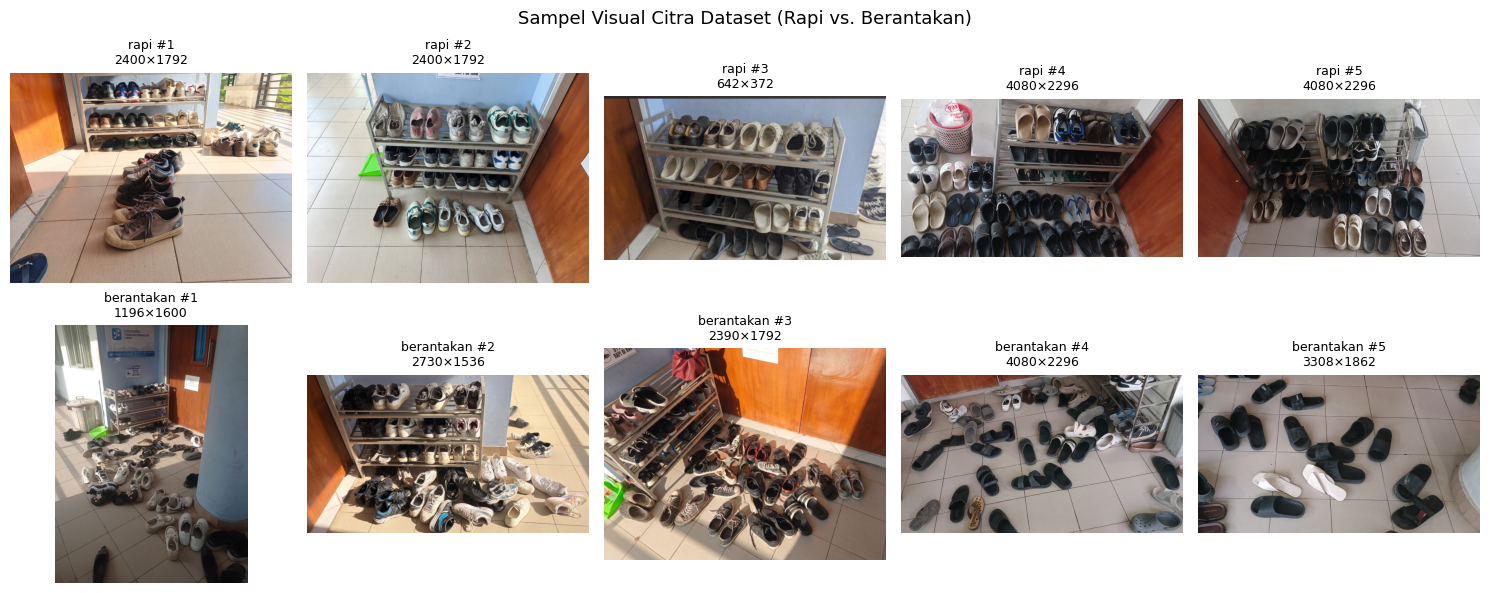

In [20]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def baca_citra(path):
    """Baca citra berwarna (BGR). imdecode dipakai sebagai cadangan untuk path Windows."""
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        img = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_COLOR)
    return img

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for b, kelas in enumerate(KELAS):
    for k, (_, r) in enumerate(df[df["label"] == kelas].head(5).iterrows()):
        img = baca_citra(r["path"])
        axes[b, k].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axes[b, k].set_title(f"{kelas} #{k + 1}\n{img.shape[1]}×{img.shape[0]}", fontsize=9)
        axes[b, k].axis("off")
plt.suptitle("Sampel Visual Citra Dataset (Rapi vs. Berantakan)", fontsize=13)
plt.tight_layout()
plt.show()

---

## TAHAP 3: DATA PREPARATION (Preprocessing & Ekstraksi Fitur)

### 3.1 Preprocessing Citra
- **Pengertian**: Menyeragamkan format dan ukuran seluruh citra sebelum fitur dihitung.
- **Langkah**:
  1. **Konversi BGR → RGB**: OpenCV membaca citra dengan urutan kanal Biru-Hijau-Merah, sehingga perlu dibalik menjadi Merah-Hijau-Biru.
  2. **Resize 256 × 256 piksel** dengan interpolasi `INTER_AREA` (rata-rata area, cocok untuk memperkecil gambar tanpa efek bergerigi).
- **Alasan**: Ukuran foto antar-anggota sangat berbeda. Dengan ukuran yang sama, jumlah piksel setiap citra sama ($256 \times 256 = 65.536$), sehingga nilai fitur dapat dibandingkan secara adil dan perhitungan lebih cepat.

Jumlah citra diproses: 194
Ukuran array         : (256, 256, 3) | tipe: uint8 | rentang nilai: 4 - 255


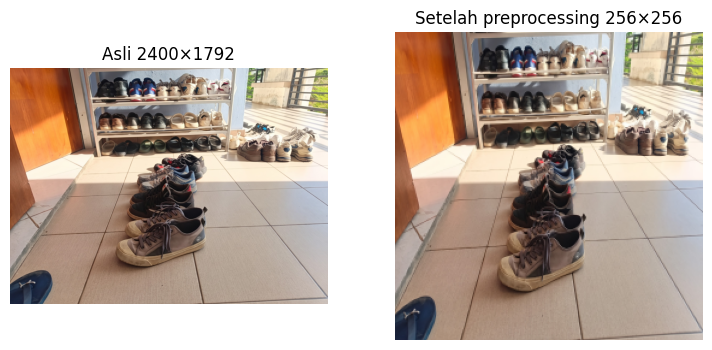

In [21]:
import cv2
import matplotlib.pyplot as plt

def preprocessing(path):
    img = baca_citra(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return cv2.resize(img, UKURAN, interpolation=cv2.INTER_AREA)

citra_rgb = {r["id"]: preprocessing(r["path"]) for _, r in df.iterrows()}

contoh = citra_rgb[1]
print("Jumlah citra diproses:", len(citra_rgb))
print("Ukuran array         :", contoh.shape, "| tipe:", contoh.dtype, "| rentang nilai:", contoh.min(), "-", contoh.max())

asli = cv2.cvtColor(baca_citra(df.loc[0, "path"]), cv2.COLOR_BGR2RGB)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(asli);   axes[0].set_title(f"Asli {asli.shape[1]}×{asli.shape[0]}")
axes[1].imshow(contoh); axes[1].set_title("Setelah preprocessing 256×256")
for ax in axes: ax.axis("off")
plt.show()

### 3.2 Fitur Statistik Warna Orde Pertama (9 Fitur)

#### Teori & Formulasi Matematis
Statistik **orde pertama** mengukur sebaran nilai intensitas piksel pada setiap kanal warna Merah ($R$), Hijau ($G$), dan Biru ($B$) **tanpa memperhitungkan hubungan antar-piksel**. Untuk kanal $C \in \{R, G, B\}$ pada citra berukuran $M \times N$:

#### 1. Mean / Rerata (`mean_r`, `mean_g`, `mean_b`) — Pers. (2)
$$\mu_C = \frac{1}{MN}\sum_{i=1}^{M}\sum_{j=1}^{N} C(i,j)$$
- **Pengertian**: Rata-rata nilai intensitas piksel pada satu kanal (0–255).
- **Makna**: Menunjukkan kecerahan dan warna dominan citra. Nilai `mean_r` tinggi berarti citra cenderung kemerahan atau terang.

#### 2. Standar Deviasi (`std_r`, `std_g`, `std_b`) — Pers. (3)
$$\sigma_C = \sqrt{\frac{1}{MN}\sum_{i=1}^{M}\sum_{j=1}^{N}\big(C(i,j)-\mu_C\big)^2}$$
- **Pengertian**: Rata-rata jarak nilai piksel terhadap *mean*-nya.
- **Makna**: Mengukur kontras atau keragaman warna. Nilai tinggi berarti citra memiliki banyak bagian gelap dan terang sekaligus.

#### 3. Skewness / Kemencengan (`skew_r`, `skew_g`, `skew_b`) — Pers. (4)
$$\theta_C = \frac{1}{MN}\sum_{i=1}^{M}\sum_{j=1}^{N}\left(\frac{C(i,j)-\mu_C}{\sigma_C}\right)^3$$
- **Pengertian**: Derajat ketidaksimetrisan sebaran nilai piksel terhadap *mean*.
- **Makna**: Positif berarti sebagian besar piksel gelap dengan sedikit piksel sangat terang; negatif berarti sebagian besar piksel terang dengan sedikit piksel sangat gelap; mendekati 0 berarti sebaran simetris.

#### Relevansi pada Penataan Sepatu
Pada susunan berantakan, sepatu tersebar menutupi lantai dan sebagian terbalik memperlihatkan sol, sehingga proporsi warna lantai dan sepatu dalam foto berubah dibandingkan rak yang tertata. Perubahan proporsi ini dapat tercermin pada *mean*, standar deviasi, dan *skewness* tiap kanal. Namun fitur orde pertama meringkas seluruh gambar tanpa melihat **letak** piksel, sehingga tidak menangkap susunan secara langsung.

#### Contoh Perhitungan Satu Citra
Rumus ditulis manual sesuai Pers. (2)–(4), lalu dicocokkan dengan `numpy` dan `scipy`.

In [22]:
import numpy as np
from scipy.stats import skew

def mean_kanal(x):
    return x.sum() / x.size                                            # Pers. (2)

def std_kanal(x):
    return np.sqrt(np.sum((x - mean_kanal(x)) ** 2) / x.size)          # Pers. (3)

def skew_kanal(x):
    mu, sd = mean_kanal(x), std_kanal(x)
    return 0.0 if sd == 0 else np.sum(((x - mu) / sd) ** 3) / x.size  # Pers. (4)

def fitur_orde1(rgb):
    f = {}
    for stat, fungsi in [("mean", mean_kanal), ("std", std_kanal), ("skew", skew_kanal)]:
        for i, kanal in enumerate("rgb"):
            f[f"{stat}_{kanal}"] = fungsi(rgb[:, :, i].astype(np.float64))
    return f

rgb = citra_rgb[1]
R = rgb[:, :, 0].astype(np.float64)
print("Citra:", df.loc[0, "label"], "/", df.loc[0, "nama_file"], "\n")
print("Nilai kanal R, 5×5 piksel pertama:")
print(rgb[:5, :5, 0], "\n")
print(f"mean_r = {R.sum():.0f} / {R.size} = {mean_kanal(R):.4f}")
print(f"std_r  = {std_kanal(R):.4f}")
print(f"skew_r = {skew_kanal(R):.4f}")
print(f"\nCek library -> numpy mean: {R.mean():.4f} | numpy std: {R.std():.4f} | scipy skew: {skew(R.ravel()):.4f}")

Citra: rapi / 24-003 Rapi 2.jpg 

Nilai kanal R, 5×5 piksel pertama:
[[181 183 185 182 185]
 [183 184 186 184 184]
 [185 186 186 185 185]
 [186 187 187 187 184]
 [186 186 187 189 185]] 

mean_r = 10979096 / 65536 = 167.5277
std_r  = 58.7598
skew_r = -0.7423

Cek library -> numpy mean: 167.5277 | numpy std: 58.7598 | scipy skew: -0.7423


#### Ekstraksi Seluruh Citra dan Penyimpanan CSV
Fitur dihitung untuk semua citra, lalu disimpan ke `hasil/fitur_warna.csv` dengan kolom `id`, `nama_file`, 9 fitur, dan `label`.

In [23]:
import os
import pandas as pd

FITUR_ORDE1 = [f"{s}_{k}" for s in ("mean", "std", "skew") for k in "rgb"]

orde1 = pd.DataFrame([fitur_orde1(citra_rgb[i]) for i in df["id"]])[FITUR_ORDE1]
fitur_warna = pd.concat([df[["id", "nama_file"]], orde1.round(4), df[["label"]]], axis=1)

fitur_warna.to_csv(os.path.join(FOLDER_HASIL, "fitur_warna.csv"), index=False)
print("Disimpan:", os.path.join(FOLDER_HASIL, "fitur_warna.csv"), "| ukuran:", fitur_warna.shape)
fitur_warna.head()

Disimpan: hasil\fitur_warna.csv | ukuran: (194, 12)


,id,nama_file,mean_r,mean_g,mean_b,std_r,std_g,std_b,skew_r,skew_g,skew_b,label
0,1,24-003 Rapi 2.jpg,167.5277,145.6219,129.1982,58.7598,58.7238,59.4027,-0.7423,-0.3384,-0.1417,rapi
1,2,24-003 Rapi 3.jpg,151.7979,144.1809,136.9614,54.8708,62.4687,69.7364,-0.6127,-0.2997,-0.2497,rapi
2,3,24-003 Rapi.jpeg,112.6111,105.5900,102.3779,50.9505,56.4039,62.8547,0.0469,0.1900,0.2648,rapi
3,4,24-006 Rapi 1.jpg,99.6618,84.9688,82.1308,61.3118,59.8151,61.1633,0.3082,0.8236,0.8788,rapi
4,5,24-006 Rapi 2.jpg,111.9111,102.2413,99.2738,63.3843,66.3158,67.5407,-0.0223,0.2308,0.2786,rapi


### 3.3 Konversi Citra ke Grayscale 8 Bit

#### Teori & Formulasi Matematis
- **Pengertian**: Citra grayscale hanya memiliki satu kanal berisi tingkat keabuan, dari 0 (hitam) sampai 255 (putih).
- **Rumus *luminosity***:
$$Gray(i,j) = 0.299\,R(i,j) + 0.587\,G(i,j) + 0.114\,B(i,j)$$
  Bobot hijau paling besar karena mata manusia paling peka terhadap warna hijau, sedangkan biru paling kecil.
- **8 bit**: hasil dibulatkan menjadi bilangan bulat, sehingga terdapat $2^8 = 256$ level keabuan.

#### Relevansi
GLCM (Tahap 3.4) dihitung dari pasangan nilai keabuan, sehingga citra harus diubah ke satu kanal terlebih dahulu. Hasil konversi disimpan ke `grayscale/rapi/` dan `grayscale/berantakan/` dalam format PNG, karena PNG tidak mengubah nilai piksel saat disimpan (berbeda dengan JPG).

Citra grayscale disimpan: 194 file -> grayscale/

Contoh piksel (0,0): R=181, G=86, B=40
Gray = 0.299×181 + 0.587×86 + 0.114×40 = 109.16 -> 109
Ukuran: (256, 256) | tipe: uint8 | rentang nilai: 11 - 254


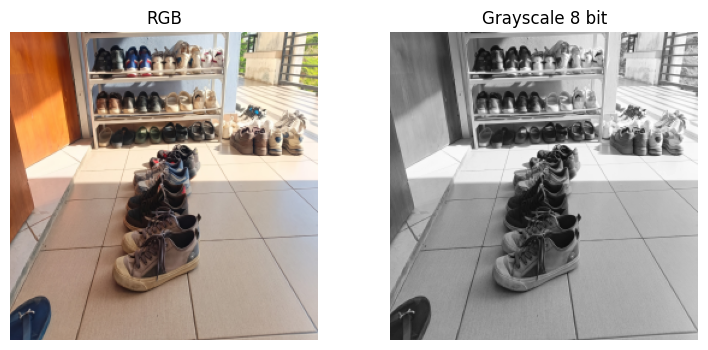

In [24]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

def ke_gray(rgb):
    r, g, b = [rgb[:, :, i].astype(np.float64) for i in range(3)]
    gray = 0.299 * r + 0.587 * g + 0.114 * b
    return np.clip(np.round(gray), 0, 255).astype(np.uint8)

citra_gray = {i: ke_gray(citra_rgb[i]) for i in df["id"]}

for _, r in df.iterrows():
    out = os.path.join(FOLDER_GRAY, r["label"], os.path.splitext(r["nama_file"])[0] + ".png")
    cv2.imencode(".png", citra_gray[r["id"]])[1].tofile(out)
print("Citra grayscale disimpan:", len(citra_gray), "file ->", FOLDER_GRAY + "/")

rgb, gray = citra_rgb[1], citra_gray[1]
r_, g_, b_ = rgb[0, 0].astype(int)
print(f"\nContoh piksel (0,0): R={r_}, G={g_}, B={b_}")
print(f"Gray = 0.299×{r_} + 0.587×{g_} + 0.114×{b_} = {0.299*r_ + 0.587*g_ + 0.114*b_:.2f} -> {gray[0, 0]}")
print("Ukuran:", gray.shape, "| tipe:", gray.dtype, "| rentang nilai:", gray.min(), "-", gray.max())

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(rgb);                                 axes[0].set_title("RGB")
axes[1].imshow(gray, cmap="gray", vmin=0, vmax=255); axes[1].set_title("Grayscale 8 bit")
for ax in axes: ax.axis("off")
plt.show()

### 3.4 Pembentukan Matriks Co-occurrence (GLCM)

#### Teori & Formulasi Matematis
- **Pengertian**: *Gray-Level Co-occurrence Matrix* (GLCM) adalah matriks yang mencatat **seberapa sering pasangan nilai keabuan $(i, j)$ muncul berdampingan** pada jarak dan arah tertentu. Karena melibatkan pasangan piksel, fitur yang dihitung dari GLCM disebut statistik **orde kedua**.
- **Parameter** (sesuai modul):

| Parameter | Nilai | Arti |
| :--- | :--- | :--- |
| Jarak $d$ | 1 | piksel dipasangkan dengan tetangga tepat di sebelahnya |
| Sudut $\theta$ | 0° | arah horizontal (tetangga kanan) |
| Level | 256 | sesuai grayscale 8 bit, sehingga GLCM berukuran 256 × 256 |
| `symmetric` | `False` | pasangan $(i, j)$ dan $(j, i)$ dihitung terpisah |
| `normed` | `True` | GLCM dinormalisasi menjadi peluang $P(i,j)$ |

- **Langkah**:
  1. **Tabulasi**: hitung frekuensi setiap pasangan (baris $i$ = piksel referensi, kolom $j$ = piksel tetangga).
  2. **Normalisasi**:
$$P(i,j) = \frac{GLCM(i,j)}{\sum_{i}\sum_{j} GLCM(i,j)}, \qquad \sum_{i}\sum_{j} P(i,j) = 1$$

#### Contoh Citra 3 × 3 dari Modul
Citra 3 × 3 memiliki 2 pasangan horizontal per baris, sehingga total ada 6 pasangan. Hasil hitung manual dibandingkan dengan `graycomatrix`.

In [25]:
import numpy as np
from skimage.feature import graycomatrix

contoh = np.array([[0, 1, 1],
                   [0, 2, 1],
                   [2, 2, 0]], dtype=np.uint8)

# Manual: pasangkan setiap piksel dengan tetangga kanannya
manual = np.zeros((3, 3), dtype=int)
for baris_px in contoh:
    for i, j in zip(baris_px[:-1], baris_px[1:]):
        manual[i, j] += 1

lib = graycomatrix(contoh, distances=[1], angles=[0], levels=3, symmetric=False, normed=False)[:, :, 0, 0]

print("GLCM manual:\n", manual)
print("\nGLCM graycomatrix:\n", lib)
print("\nSama persis:", np.array_equal(manual, lib), "| total pasangan:", manual.sum())
print("\nGLCM ternormalisasi P(i,j):\n", np.round(manual / manual.sum(), 3))

GLCM manual:
 [[0 1 1]
 [0 1 0]
 [1 1 1]]

GLCM graycomatrix:
 [[0 1 1]
 [0 1 0]
 [1 1 1]]

Sama persis: True | total pasangan: 6

GLCM ternormalisasi P(i,j):
 [[0.    0.167 0.167]
 [0.    0.167 0.   ]
 [0.167 0.167 0.167]]


#### GLCM pada Citra Sepatu
Citra 256 × 256 menghasilkan $256 \times 255 = 65.280$ pasangan horizontal dan GLCM berukuran 256 × 256. Yang ditampilkan adalah potongan di sekitar nilai keabuan dominan serta *heatmap* seluruh matriks (skala log agar sel bernilai kecil tetap terlihat). Isi GLCM terkumpul di sekitar **diagonal**, artinya piksel bertetangga umumnya memiliki nilai keabuan yang mirip.

Citra          : rapi / 24-003 Rapi 2.jpg
Ukuran GLCM    : (256, 256)
Total pasangan : 65280
Jumlah P(i,j)  : 1.0

Potongan GLCM mentah (level 154-162):
     154  155  156  157  158  159  160  161  162
154   81   57   41   29   12   14   13   11    5
155   50   60   60   34   20   19   10   13    5
156   44   50   64   55   33   19   17   16    5
157   29   29   53   49   44   22   22   12    7
158   15   25   32   41   44   30   25   14   11
159   12   15   21   22   39   47   29   17   22
160   10   10   11   16   19   31   32   25   29
161    1    6    4   15   15   17   31   51   31
162    1    3    5    5    8   18   30   33   43


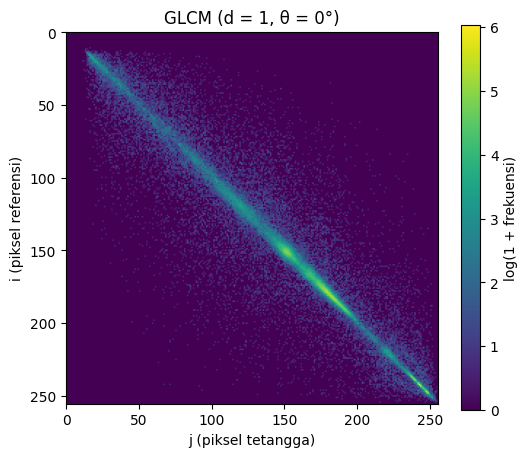

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.feature import graycomatrix

def buat_glcm(gray, levels=256, normed=True):
    return graycomatrix(gray, distances=[1], angles=[0], levels=levels, symmetric=False, normed=normed)

gray = citra_gray[1]
mentah = buat_glcm(gray, normed=False)[:, :, 0, 0]
P = buat_glcm(gray)[:, :, 0, 0]

print("Citra          :", df.loc[0, "label"], "/", df.loc[0, "nama_file"])
print("Ukuran GLCM    :", P.shape)
print("Total pasangan :", mentah.sum())
print("Jumlah P(i,j)  :", round(P.sum(), 6))

m = int(np.median(gray))
r = range(max(m - 4, 0), min(m + 5, 256))
print(f"\nPotongan GLCM mentah (level {r.start}-{r.stop - 1}):")
print(pd.DataFrame(mentah[np.ix_(r, r)], index=r, columns=r).to_string())

plt.figure(figsize=(6, 5))
plt.imshow(np.log1p(mentah), cmap="viridis")
plt.colorbar(label="log(1 + frekuensi)")
plt.title("GLCM (d = 1, θ = 0°)")
plt.xlabel("j (piksel tetangga)"); plt.ylabel("i (piksel referensi)")
plt.show()

### 3.5 Fitur Tekstur Orde Kedua dari GLCM (5 Fitur)

#### Teori & Formulasi Matematis
Kelima fitur dihitung dari GLCM ternormalisasi $P(i,j)$, dengan
$\mu_i = \sum_{i,j} i\,P(i,j)$, $\mu_j = \sum_{i,j} j\,P(i,j)$, $\sigma_i = \sqrt{\sum_{i,j}(i-\mu_i)^2P(i,j)}$, dan $\sigma_j = \sqrt{\sum_{i,j}(j-\mu_j)^2P(i,j)}$.

#### 1. Energi (`energi`) — Pers. (8)
$$Energi = \sum_{i}\sum_{j} P(i,j)^2$$
- **Pengertian**: Disebut juga *Angular Second Moment* (ASM); jumlah kuadrat seluruh elemen GLCM.
- **Makna**: Bernilai tinggi jika hanya sedikit pasangan keabuan yang mendominasi, yaitu tekstur **seragam** seperti lantai atau dinding polos.

#### 2. Entropi (`entropi`) — Pers. (5)
$$Entropi = -\sum_{i}\sum_{j} P(i,j)\,\log_2 P(i,j)$$
- **Pengertian**: Ukuran ketidakpastian atau keacakan distribusi pasangan keabuan; sel bernilai 0 dilewati karena $0 \cdot \log_2 0 = 0$.
- **Makna**: Bernilai tinggi pada tekstur **kompleks dan acak**; berlawanan arah dengan energi.

#### 3. Kontras (`kontras`) — Pers. (6)
$$Kontras = \sum_{i}\sum_{j} (i-j)^2\,P(i,j)$$
- **Pengertian**: Rata-rata kuadrat selisih nilai keabuan antar-piksel bertetangga.
- **Makna**: Bernilai tinggi jika banyak **perubahan tajam** (tepi objek), rendah jika citra halus.

#### 4. Korelasi (`korelasi`) — Pers. (7)
$$Korelasi = \sum_{i}\sum_{j} \frac{(i-\mu_i)(j-\mu_j)\,P(i,j)}{\sigma_i\,\sigma_j}$$
- **Pengertian**: Ukuran keterkaitan linier antara nilai piksel dan tetangganya, bernilai −1 sampai 1.
- **Makna**: Mendekati 1 berarti nilai piksel dan tetangganya bergerak searah (area luas yang berubah perlahan).

#### 5. Homogenitas (`homogenitas`) — Pers. (9)
$$Homogenitas = \sum_{i}\sum_{j} \frac{P(i,j)}{1 + \lvert i-j \rvert}$$
- **Pengertian**: Disebut juga *Inverse Difference Moment*; memberi bobot besar pada elemen di dekat diagonal GLCM.
- **Makna**: Bernilai tinggi jika piksel bertetangga bernilai **mirip** (transisi halus).

#### Relevansi pada Penataan Sepatu
Rak yang rapi memiliki bidang-bidang yang tertata (rak, lantai kosong), sehingga diharapkan energi dan homogenitas lebih tinggi. Sepatu yang berserakan menambah banyak tepi dan pola acak di lantai, sehingga diharapkan entropi dan kontras lebih tinggi. Dugaan ini diperiksa pada Tahap 3.7.

In [27]:
import numpy as np

def energi(P):
    return np.sum(P ** 2)                                        # Pers. (8)

def entropi(P):
    nz = P[P > 0]
    return -np.sum(nz * np.log2(nz))                             # Pers. (5)

def kontras(P):
    i, j = np.indices(P.shape)
    return np.sum((i - j) ** 2 * P)                              # Pers. (6)

def korelasi(P):
    i, j = np.indices(P.shape)
    mu_i, mu_j = np.sum(i * P), np.sum(j * P)
    sd_i = np.sqrt(np.sum((i - mu_i) ** 2 * P))
    sd_j = np.sqrt(np.sum((j - mu_j) ** 2 * P))
    if sd_i * sd_j == 0:
        return 1.0
    return np.sum((i - mu_i) * (j - mu_j) * P) / (sd_i * sd_j)   # Pers. (7)

def homogenitas(P):
    i, j = np.indices(P.shape)
    return np.sum(P / (1 + np.abs(i - j)))                       # Pers. (9)

FITUR_ORDE2 = ["energi", "entropi", "kontras", "korelasi", "homogenitas"]
FUNGSI_ORDE2 = [energi, entropi, kontras, korelasi, homogenitas]

def fitur_orde2(gray, levels=256):
    P = buat_glcm(gray, levels=levels)[:, :, 0, 0]
    return {nama: fungsi(P) for nama, fungsi in zip(FITUR_ORDE2, FUNGSI_ORDE2)}

#### Verifikasi Perhitungan
**Contoh 3 × 3 modul.** Dengan $P(i,j)$ dari Tahap 3.4 (enam sel bernilai $1/6$):
- energi $= 6 \times (1/6)^2 = 0{,}1667$
- entropi $= -6 \times \tfrac16 \log_2 \tfrac16 = \log_2 6 = 2{,}5850$
- kontras $= \tfrac16\,(1 + 4 + 0 + 4 + 1 + 0) = 1{,}6667$

**Citra sepatu.** Hasil manual dibandingkan dengan `graycoprops` dari scikit-image:
- **kontras** dan **korelasi** harus sama persis;
- **energi** dibandingkan dengan `ASM`, karena `energy` di scikit-image adalah $\sqrt{ASM}$;
- **homogenitas** tidak dibandingkan, karena scikit-image memakai penyebut $1+(i-j)^2$, sedangkan Pers. (9) memakai $1+\lvert i-j \rvert$.

In [28]:
from skimage.feature import graycoprops

print("Contoh 3x3 :", {k: round(float(v), 4) for k, v in fitur_orde2(contoh, levels=3).items()})

glcm = buat_glcm(citra_gray[1])
P = glcm[:, :, 0, 0]
print(f"\n{'fitur':10} {'manual':>12} {'graycoprops':>12}")
for nama, manual, lib in [("energi",   energi(P),   graycoprops(glcm, "ASM")[0, 0]),
                          ("kontras",  kontras(P),  graycoprops(glcm, "contrast")[0, 0]),
                          ("korelasi", korelasi(P), graycoprops(glcm, "correlation")[0, 0])]:
    print(f"{nama:10} {manual:12.6f} {lib:12.6f}")

Contoh 3x3 : {'energi': 0.1667, 'entropi': 2.585, 'kontras': 1.6667, 'korelasi': -0.3153, 'homogenitas': 0.6111}

fitur            manual  graycoprops
energi         0.000696     0.000696
kontras      300.062408   300.062408
korelasi       0.954200     0.954200


#### Ekstraksi Seluruh Citra dan Penyimpanan CSV
Fitur dihitung untuk semua citra grayscale, lalu disimpan ke `hasil/fitur_glcm.csv` dengan kolom `id`, `nama_file`, 5 fitur, dan `label`.

In [29]:
import os
import pandas as pd

orde2 = pd.DataFrame([fitur_orde2(citra_gray[i]) for i in df["id"]])[FITUR_ORDE2]
fitur_glcm = pd.concat([df[["id", "nama_file"]], orde2.round(8), df[["label"]]], axis=1)

fitur_glcm.to_csv(os.path.join(FOLDER_HASIL, "fitur_glcm.csv"), index=False)
print("Disimpan:", os.path.join(FOLDER_HASIL, "fitur_glcm.csv"), "| ukuran:", fitur_glcm.shape)
fitur_glcm.head()

Disimpan: hasil\fitur_glcm.csv | ukuran: (194, 8)


,id,nama_file,energi,entropi,kontras,korelasi,homogenitas,label
0,1,24-003 Rapi 2.jpg,0.000696,12.092472,300.062408,0.954200,0.370522,rapi
1,2,24-003 Rapi 3.jpg,0.000607,12.105675,340.629779,0.951172,0.387804,rapi
2,3,24-003 Rapi.jpeg,0.000420,12.436947,258.886167,0.956552,0.339651,rapi
3,4,24-006 Rapi 1.jpg,0.000392,12.590984,424.356556,0.939107,0.312549,rapi
4,5,24-006 Rapi 2.jpg,0.000749,12.022263,382.180239,0.954788,0.404929,rapi


### 3.6 Penggabungan Fitur Menjadi Dataset Akhir
Fitur orde pertama dan orde kedua digabung berdasarkan kunci `id`, `nama_file`, dan `label`:

In [30]:
import os

FITUR = FITUR_ORDE1 + FITUR_ORDE2
fitur_lengkap = fitur_warna.merge(fitur_glcm, on=["id", "nama_file", "label"])
fitur_lengkap = fitur_lengkap[["id", "nama_file"] + FITUR + ["label"]]

fitur_lengkap.to_csv(os.path.join(FOLDER_HASIL, "fitur_lengkap.csv"), index=False)

print("=== RINGKASAN DATASET FITUR ===")
print("Disimpan     :", os.path.join(FOLDER_HASIL, "fitur_lengkap.csv"))
print("Jumlah citra :", len(fitur_lengkap), fitur_lengkap["label"].value_counts().to_dict())
print("Jumlah fitur :", len(FITUR), "(9 orde pertama + 5 orde kedua) + label")
print("Data kosong  :", int(fitur_lengkap[FITUR].isna().sum().sum()))
fitur_lengkap

=== RINGKASAN DATASET FITUR ===
Disimpan     : hasil\fitur_lengkap.csv
Jumlah citra : 194 {'rapi': 97, 'berantakan': 97}
Jumlah fitur : 14 (9 orde pertama + 5 orde kedua) + label
Data kosong  : 0


,id,nama_file,mean_r,mean_g,mean_b,std_r,std_g,std_b,skew_r,skew_g,skew_b,energi,entropi,kontras,korelasi,homogenitas,label
0,1,24-003 Rapi 2.jpg,167.5277,145.6219,129.1982,58.7598,58.7238,59.4027,-0.7423,-0.3384,-0.1417,0.000696,12.092472,300.062408,0.954200,0.370522,rapi
1,2,24-003 Rapi 3.jpg,151.7979,144.1809,136.9614,54.8708,62.4687,69.7364,-0.6127,-0.2997,-0.2497,0.000607,12.105675,340.629779,0.951172,0.387804,rapi
2,3,24-003 Rapi.jpeg,112.6111,105.5900,102.3779,50.9505,56.4039,62.8547,0.0469,0.1900,0.2648,0.000420,12.436947,258.886167,0.956552,0.339651,rapi
3,4,24-006 Rapi 1.jpg,99.6618,84.9688,82.1308,61.3118,59.8151,61.1633,0.3082,0.8236,0.8788,0.000392,12.590984,424.356556,0.939107,0.312549,rapi
4,5,24-006 Rapi 2.jpg,111.9111,102.2413,99.2738,63.3843,66.3158,67.5407,-0.0223,0.2308,0.2786,0.000749,12.022263,382.180239,0.954788,0.404929,rapi
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
189,190,24-202 berantakan 2.jpeg,162.5147,155.9527,151.1941,48.9482,49.6319,49.0260,-0.9544,-0.7081,-0.5954,0.001264,11.589593,251.846829,0.947328,0.403538,berantakan
190,191,24-202 berantakan 3.jpeg,151.2810,140.9007,137.2909,40.4139,52.5318,57.2555,-0.8206,-0.4817,-0.3711,0.001760,11.086140,202.731602,0.956330,0.444838,berantakan
191,192,24-228 Berantakan 1.jpeg,141.3388,135.5317,132.2635,55.4292,60.7127,67.0456,-0.4541,-0.3250,-0.2794,0.005789,10.661901,185.444623,0.973231,0.484861,berantakan
192,193,24-228 Berantakan 2.jpeg,131.9589,133.6299,134.0795,52.4653,55.4021,59.9147,-0.6674,-0.4358,-0.1064,0.001370,11.451288,172.177267,0.970347,0.457050,berantakan
